# Customer Segmentation and Churn Risk

EdVyro Data Analytics Internship - Task 4 | Dhaksith-S

## 1. Project introduction
This analysis turns a small synthetic subscription sample into auditable customer cohorts and an explainable prioritization index. The three deliverables are this notebook, the customer segment table, and the recommendation memo. Scores are not churn probabilities.

## 2. Business problem
Which groups warrant service investigation, and how could a future retention team prioritize active customers? Historical churn and current retention eligibility must be distinguished. We do not estimate intervention effects from these data.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.pipeline import locate_source, run_pipeline
from src.preprocessing import profile_data
from src.segmentation import summarize, SEGMENTS
from src.scoring import RULES, calculate_risk_score, assign_risk_band, explain_risk_score
raw = pd.read_csv(locate_source())
df, profile, cleaning_log = run_pipeline(root=ROOT)
pd.set_option('display.max_columns', 25)
def chart(name): display(Image(filename=str(ROOT / 'reports/figures' / (name + '.png'))))
print('Environment: Python', sys.version.split()[0])
print(f'Source: {raw.shape[0]} customers, {raw.shape[1]} columns; {len(df)} retained records')

Environment: Python 3.11.9
Source: 15 customers, 11 columns; 15 retained records


## 3. Dataset overview
The supplied Task 1 brief identifies synthetic records. The source library defines charges in INR and support tickets in the previous 90 days. Actual CSV categories take precedence over the generic guide. Original source remains unchanged and is excluded from the public repository; see `data/README.md` for authorized retrieval. Public examples omit raw IDs and demographics.

In [2]:
display(pd.DataFrame({'dtype':raw.dtypes.astype(str), 'missing':raw.isna().sum()}))
display(df[['AnalysisID','TenureMonths','ContractType','MonthlyCharges','SupportTickets','Churned']].head())
display(raw.select_dtypes('number').describe())

,dtype,missing
CustomerID,object,0
Gender,object,0
Age,int64,0
TenureMonths,int64,0
SubscriptionType,object,0
MonthlyCharges,float64,0
TotalCharges,float64,0
ContractType,object,0
SupportTickets,int64,0
PaymentMethod,object,0


,AnalysisID,TenureMonths,ContractType,MonthlyCharges,SupportTickets,Churned
0,SYN-bf37cbae2fe0,12.0,Month-to-Month,49.99,3.0,1
1,SYN-e5a10dfc6978,24.0,One Year,79.99,1.0,0
2,SYN-e58c67ab5d88,6.0,Month-to-Month,49.99,5.0,1
3,SYN-f946d1c542f0,36.0,Two Year,149.99,0.0,0
4,SYN-0bc032d9c78d,8.0,Month-to-Month,79.99,4.0,1


,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,39.066667,18.800000,84.656667,2088.478667,2.533333
std,11.392144,14.333776,42.739521,2407.365767,1.922300
min,23.000000,2.000000,49.990000,99.980000,0.000000
25%,30.000000,7.000000,49.990000,449.910000,1.000000
50%,38.000000,15.000000,79.990000,1099.780000,2.000000
75%,47.000000,27.000000,114.990000,3209.730000,4.000000
max,60.000000,48.000000,149.990000,7199.520000,6.000000


## 4. Data quality assessment
Check original missingness, duplicate IDs, full-row duplicates, categories, numeric ranges, and the billing identity. Counts are inspected before normalization. See the full quality report for exclusion and missing-value rules.

In [3]:
print('Missing cells:', sum(profile['missing'].values()))
print('Exact duplicates:', profile['exact_duplicate_rows'], 'Duplicate IDs:', profile['duplicate_customer_ids'])
print('Billing identity mismatches:', profile['charge_identity_mismatches'])
display(pd.DataFrame([{'Column':k,'Value':v,'Count':n} for k,vs in profile['categories'].items() for v,n in vs.items()]))

Missing cells: 0
Exact duplicates: 0 Duplicate IDs: 0
Billing identity mismatches: 0


,Column,Value,Count
0,Gender,Female,8
1,Gender,Male,7
2,SubscriptionType,Basic,7
3,SubscriptionType,Pro,4
4,SubscriptionType,Enterprise,4
5,ContractType,Month-to-Month,7
6,ContractType,One Year,4
7,ContractType,Two Year,4
8,PaymentMethod,Credit Card,6
9,PaymentMethod,UPI,4


## 5. Cleaning and preprocessing
Text is trimmed and recognized categories canonicalized. Impossible numeric values become null. Exact duplicates are removed; conflicting IDs are quarantined entirely. Core inputs are never imputed: incomplete records remain Unscored. Missing labels are excluded from evaluation denominators. No source customer needed correction or removal in this run.

In [4]:
display(cleaning_log)
print(f'Cleaning events: {len(cleaning_log)}; scored: {df.ScoreEligible.sum()}; labelled/scored: {df.EvaluationEligible.sum()}')

,source_row,field,action


Cleaning events: 0; scored: 15; labelled/scored: 15


## 6. Exploratory data analysis
These are cross-sectional observed associations, with no exact observation date or outcome horizon. Category plots annotate churned/labelled counts so tiny denominators remain visible.

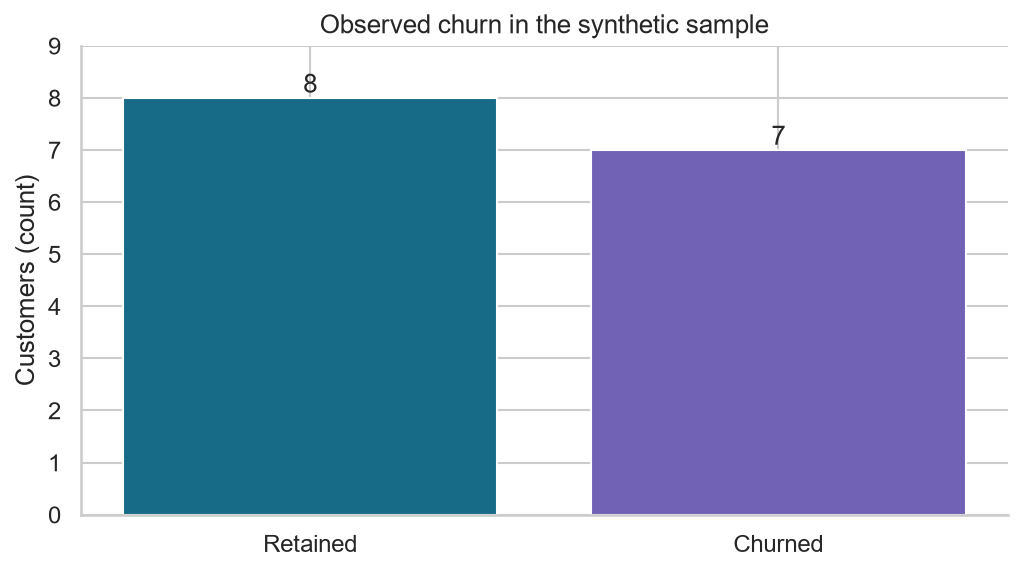

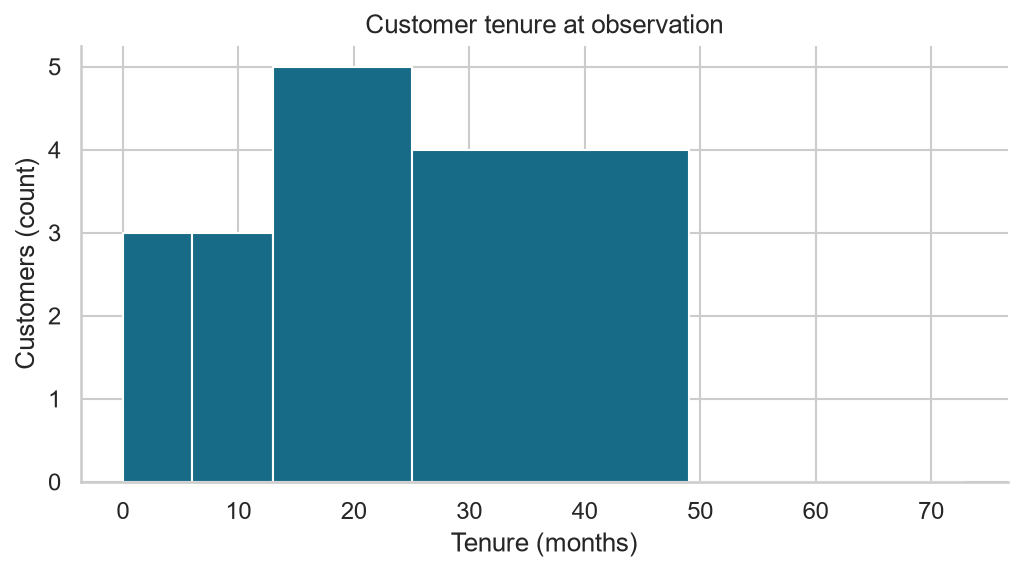

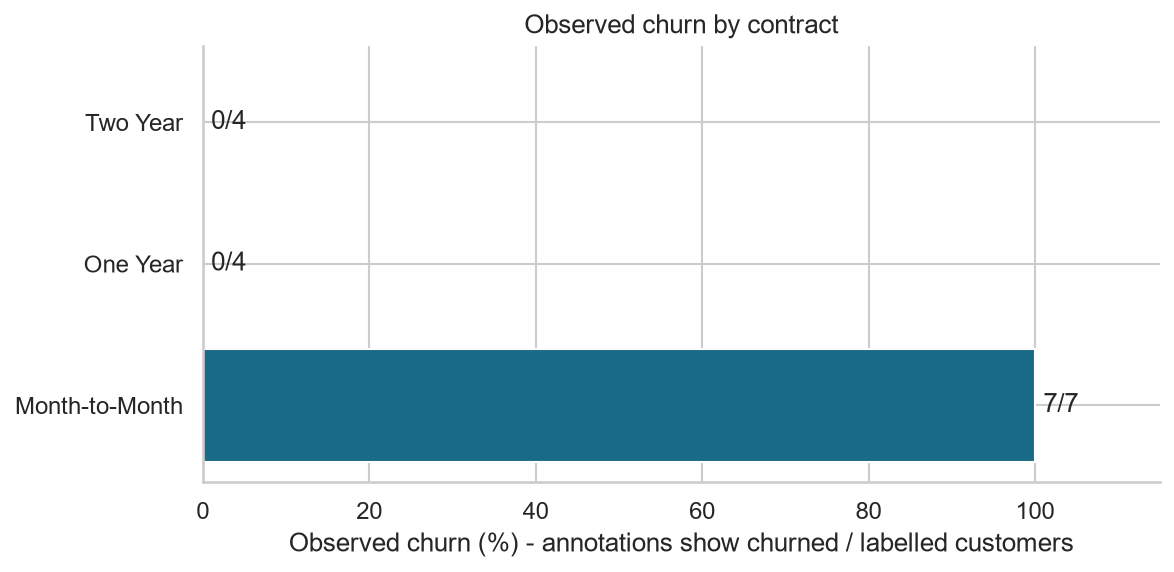

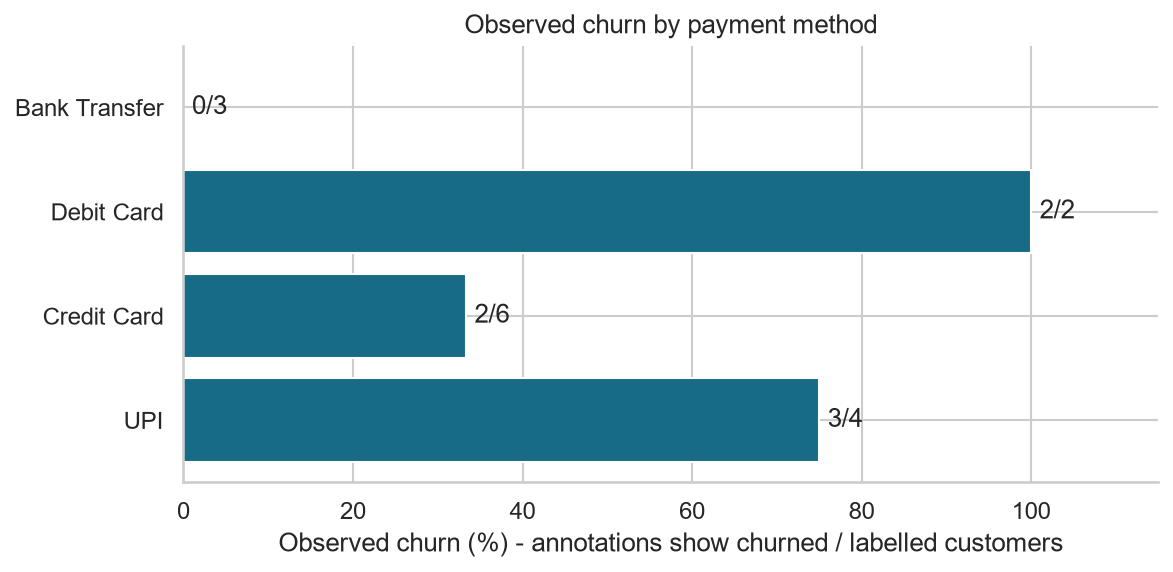

Churn: 7/15 = 46.67%
Mean tenure: 18.80 months; median 15 months


In [5]:
for name in ['churn_distribution','tenure_distribution','churn_by_contract','churn_by_payment']: chart(name)
print(f'Churn: {df.Churned.sum()}/{df.Churned.notna().sum()} = {100*df.Churned.mean():.2f}%')
print(f'Mean tenure: {df.TenureMonths.mean():.2f} months; median {df.TenureMonths.median():.0f} months')

Interpretation: all seven monthly-contract customers are churned; all eight longer-contract customers are retained. The 46.67% churn share describes this synthetic sample only. Payment contrasts are confounded by contract and tenure and do not justify payment-method penalties. Tenure spans 2-48 months; observed support counts are 0-6.

## 7. Feature selection
**Scoring inputs:** tenure (lifecycle), contract (commitment), monthly charges (absolute bill exposure). **Behavioral descriptive input:** support tickets (service demand). **Other descriptive cohorts:** payment and subscription tier. Support timing relative to churn is unknown, so tickets never enter the score. Exclude age/gender (unnecessary demographics), IDs, churn, and total charges (mechanically redundant). Even core account fields need verified pre-churn snapshots before production use.

## 8. Feature engineering
Tenure: 0-5, 6-12, 13-24, 25+ months. The 6/12/24 boundaries represent onboarding and annual review heuristics. Spending: <70, 70-<100, >=100 INR. These fixed thresholds separate the three source price tiers, not learned affordability groups. Hash synthetic IDs, map Yes/No outcome to 1/0, and preserve missingness.

In [6]:
display(df[['AnalysisID','TenureBand','SpendingBand','SubscriptionType','SupportTickets']])

,AnalysisID,TenureBand,SpendingBand,SubscriptionType,SupportTickets
0,SYN-bf37cbae2fe0,Developing (6-12),Low (<70 INR),Basic,3.0
1,SYN-e5a10dfc6978,Established (13-24),Medium (70-<100 INR),Pro,1.0
2,SYN-e58c67ab5d88,Developing (6-12),Low (<70 INR),Basic,5.0
3,SYN-f946d1c542f0,Long-term (25+),High (>=100 INR),Enterprise,0.0
4,SYN-0bc032d9c78d,Developing (6-12),Medium (70-<100 INR),Pro,4.0
5,SYN-c03569c30554,Established (13-24),Low (<70 INR),Basic,2.0
6,SYN-d847265fa76e,New (0-5),Low (<70 INR),Basic,6.0
7,SYN-ea83f48d2086,Long-term (25+),High (>=100 INR),Enterprise,1.0
8,SYN-be498ae37c70,Established (13-24),Medium (70-<100 INR),Pro,2.0
9,SYN-ba11c4e4be6a,New (0-5),Low (<70 INR),Basic,4.0


## 9. Customer segmentation methodology
Primary segments are mutually exclusive account cohorts. A flexible contract is split at the end of the first year; annual and two-year commitments form separate groups. Missing tenure or contract produces Data review. Analytical tenure/payment/risk dimensions overlap across dimensions and are presented separately.

In [7]:
display(pd.DataFrame(SEGMENTS.items(), columns=['Primary segment','Definition']))
assert df.PrimarySegment.notna().all()
assert summarize(df).Customers.sum() == len(df)

,Primary segment,Definition
0,Flexible - first year,Month-to-Month contract and tenure <=12 months
1,Flexible - beyond first year,Month-to-Month contract and tenure >12 months
2,Annual commitment,One Year contract at any known tenure
3,Two-year commitment,Two Year contract at any known tenure
4,Data review,Missing/unknown tenure or contract


## 10. Segment distribution analysis
Counts, charge sums, observed outcomes, tenure, service demand, and the full score range are available for each primary segment. Groups with fewer than five accounts are explicitly flagged.

,PrimarySegment,Definition,Customers,CustomerPct,LabeledCustomers,ChurnedCustomers,ObservedChurnPct,AvgTenureMonths,AvgMonthlyChargesINR,MonthlyChargeSumINR,RetainedMonthlyChargeSumINR,HighRiskChargeSumINR,ScoredCustomers,AvgRiskScore,MinRiskScore,MedianRiskScore,MaxRiskScore,HighRiskCustomers,AvgSupportTickets90Days,SmallSample
0,Flexible - first year,Month-to-Month contract and tenure <=12 months,6,40.000000,6,6,100.0,5.833333,54.99,329.94,0.00,329.94,6,76.666667,70,80.0,80,6,4.5,False
1,Flexible - beyond first year,Month-to-Month contract and tenure >12 months,1,6.666667,1,1,100.0,14.000000,79.99,79.99,0.00,79.99,1,65.000000,65,65.0,65,1,3.0,True
2,Annual commitment,One Year contract at any known tenure,4,26.666667,4,0,0.0,19.750000,64.99,259.96,259.96,0.00,4,35.000000,30,35.0,40,0,1.5,True
3,Two-year commitment,Two Year contract at any known tenure,4,26.666667,4,0,0.0,38.500000,149.99,599.96,599.96,0.00,4,20.000000,20,20.0,20,0,0.5,True


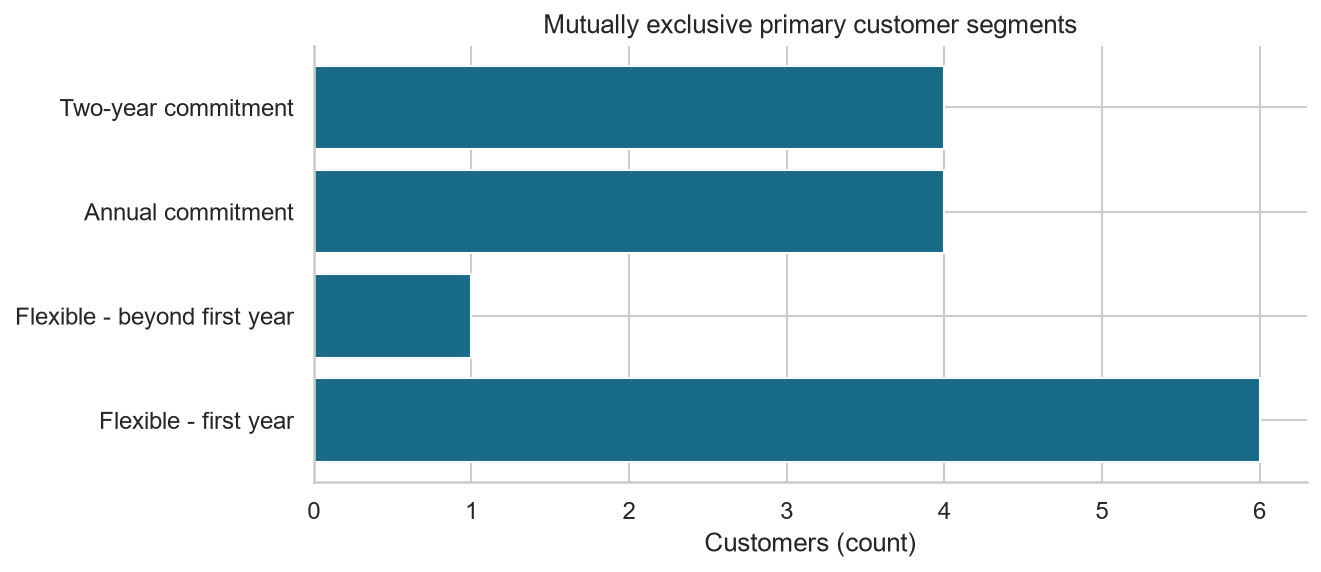

In [8]:
display(summarize(df))
chart('segment_counts')

Interpretation: the first-year flexible cohort contains six accounts. The other flexible cohort contains one, and both commitment cohorts contain four each. The singleton cannot support a general claim; the zero-churn commitment groups are also too small to imply protection.

## 11. Explainable churn-risk scoring
Index v1.0 sums fixed assumption-based contributions. No fitting, optimization, or calibrated probabilities are involved. Contract receives at most 45, tenure 35, charges 20. Payment, support, demographics, total charges and churn are absent from the implementation. Correlated account features can double-count the same underlying pattern. See the machine-readable scoring specification.

,signal,feature,condition,maximum,reason
0,Tenure,TenureMonths,0 <= months < 6: 35; 6 <= months <= 12: 25; 12...,35,Early lifecycle needs onboarding; fixed planni...
1,Commitment,ContractType,Month-to-Month: 45; One Year: 20; Two Year: 0,45,Shorter commitment permits an easier exit; ass...
2,Charge exposure,MonthlyCharges,INR >=100: 20; 70 <= INR <100: 10; 0 <= INR <7...,20,Absolute bill exposure may warrant a value rev...


Theoretical index range: 0-100; observed: 20 - 80


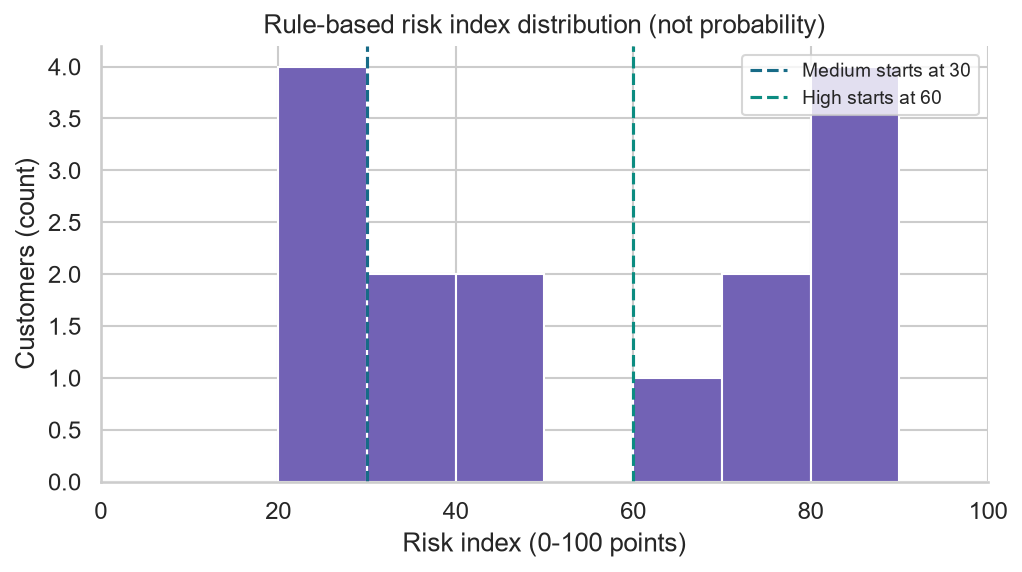

In [9]:
display(pd.DataFrame(RULES))
print('Theoretical index range: 0-100; observed:', df.RiskScore.min(), '-', df.RiskScore.max())
chart('risk_distribution')

Interpretation: actual index values span 20-80 points. Discrete point rules leave gaps in the attainable range. The 20-point charge signal is a hypothesis: the most expensive accounts in this sample are all retained.

## 12. Risk-band assignment
Low <30, Medium 30-59, High >=60. These operational planning cutoffs express accumulating indicators, not fitted decision thresholds or outreach capacity. Missing core inputs yield Unscored. They require prospective validation.

,RiskBand,Definition,Customers,CustomerPct,LabeledCustomers,ChurnedCustomers,ObservedChurnPct,AvgTenureMonths,AvgMonthlyChargesINR,MonthlyChargeSumINR,RetainedMonthlyChargeSumINR,HighRiskChargeSumINR,ScoredCustomers,AvgRiskScore,MinRiskScore,MedianRiskScore,MaxRiskScore,HighRiskCustomers,AvgSupportTickets90Days,SmallSample
0,High,Analytical cohort; not a primary segment,7,46.666667,7,7,100.0,7.00,58.561429,409.93,0.00,409.93,7,75.0,65,80.0,80,7,4.285714,False
1,Low,Analytical cohort; not a primary segment,4,26.666667,4,0,0.0,38.50,149.990000,599.96,599.96,0.00,4,20.0,20,20.0,20,0,0.500000,True
2,Medium,Analytical cohort; not a primary segment,4,26.666667,4,0,0.0,19.75,64.990000,259.96,259.96,0.00,4,35.0,30,35.0,40,0,1.500000,True


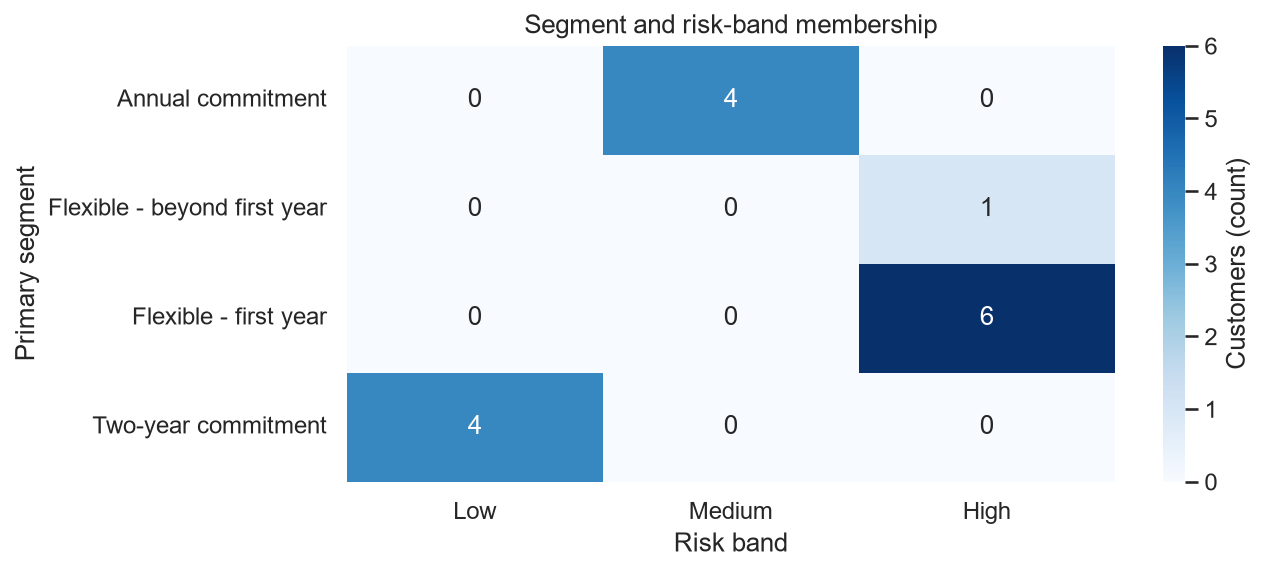

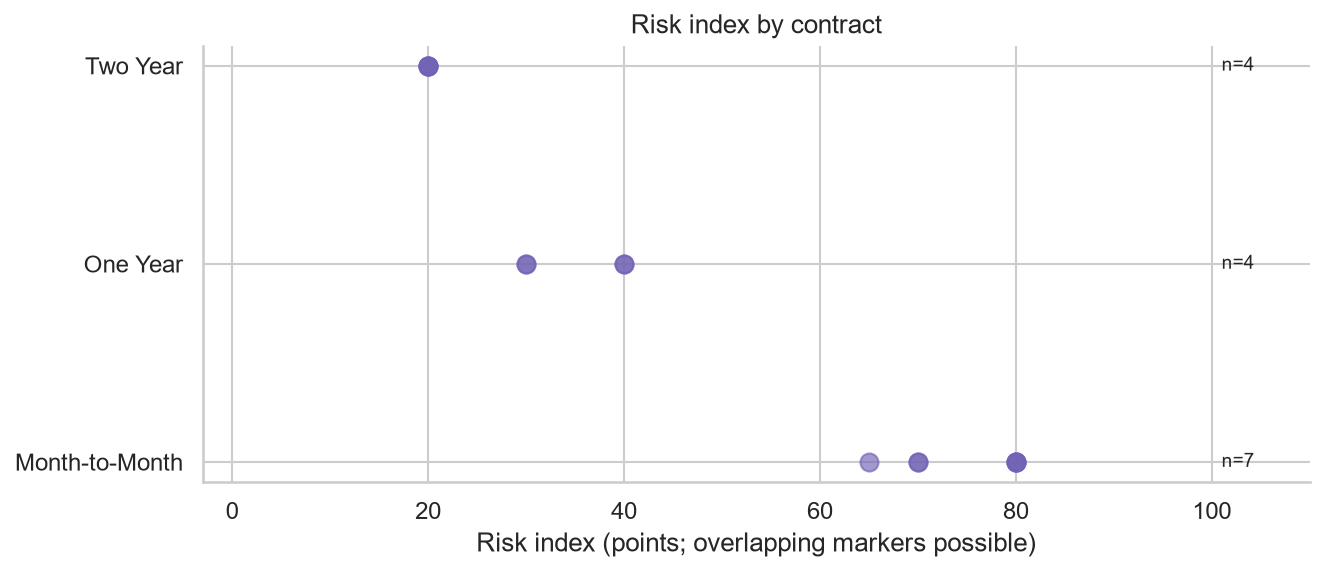

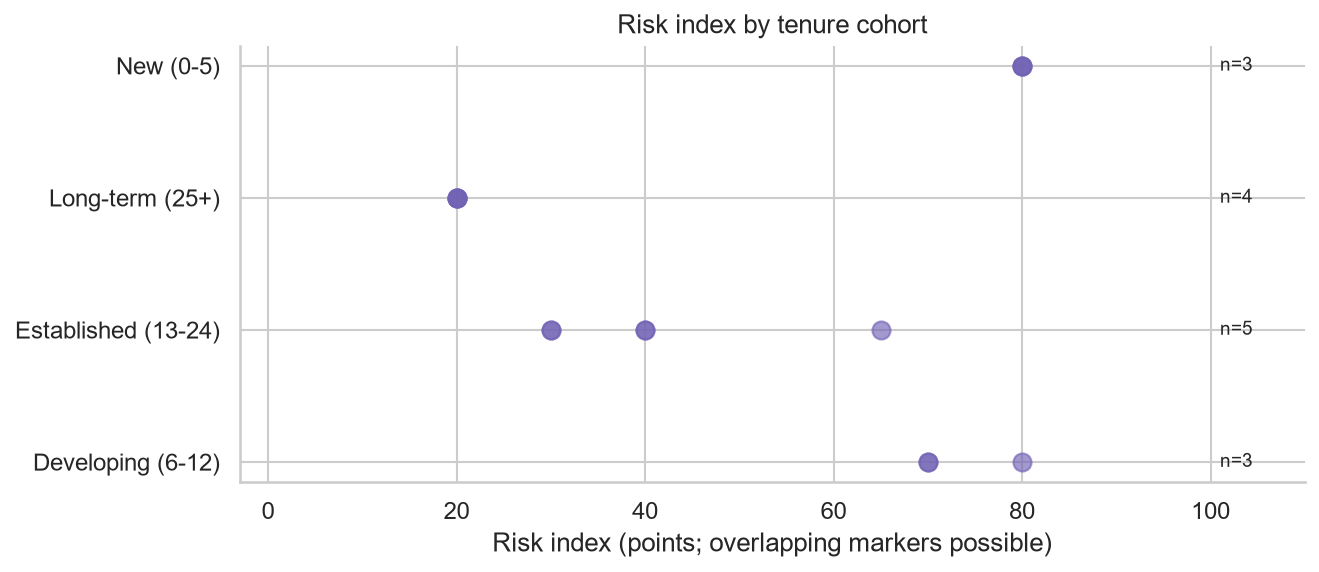

In [10]:
display(summarize(df,'RiskBand'))
chart('segment_risk_heatmap')
chart('scores_by_contract')
chart('scores_by_tenure')

Interpretation: seven High, four Medium and four Low accounts are present. The heatmap shows that each primary cohort occupies a single risk band in this particular sample. Contract alone gives the same band partition, so the extra signals have no demonstrated incremental outcome value here.

## 13. Score-level explanations
Every row exports the exact component contributions and an explanation. Zero contributions are shown. Independent reproduction needs only tenure, contract, and charges; outcomes can be changed without affecting scores.

In [11]:
display(df[['AnalysisID','TenurePoints','ContractPoints','ChargePoints','RiskScore','ScoreExplanation']])
r = df.iloc[0].to_dict()
assert calculate_risk_score(r) == calculate_risk_score({**r,'Churn':'No','Churned':0})
print(explain_risk_score(r))

,AnalysisID,TenurePoints,ContractPoints,ChargePoints,RiskScore,ScoreExplanation
0,SYN-bf37cbae2fe0,25,45,0,70,Tenure 12 months: +25; contract Month-to-Month...
1,SYN-e5a10dfc6978,10,20,10,40,Tenure 24 months: +10; contract One Year: +20;...
2,SYN-e58c67ab5d88,25,45,0,70,Tenure 6 months: +25; contract Month-to-Month:...
3,SYN-f946d1c542f0,0,0,20,20,Tenure 36 months: +0; contract Two Year: +0; m...
4,SYN-0bc032d9c78d,25,45,10,80,Tenure 8 months: +25; contract Month-to-Month:...
5,SYN-c03569c30554,10,20,0,30,Tenure 18 months: +10; contract One Year: +20;...
6,SYN-d847265fa76e,35,45,0,80,Tenure 3 months: +35; contract Month-to-Month:...
7,SYN-ea83f48d2086,0,0,20,20,Tenure 48 months: +0; contract Two Year: +0; m...
8,SYN-be498ae37c70,10,20,10,40,Tenure 15 months: +10; contract One Year: +20;...
9,SYN-ba11c4e4be6a,35,45,0,80,Tenure 4 months: +35; contract Month-to-Month:...


Tenure 12 months: +25; contract Month-to-Month: +45; monthly charge INR 49.99: +0; total 70/100. Assumption-based index, not a probability.


## 14. Retrospective churn validation
Only after scoring do we compare labels. Rules were developed after inspecting this small source; no independent holdout or temporal validation is claimed. ROC-AUC is deliberately omitted because n=15 and complete contract/outcome confounding would overstate apparent evidence. Software correctness is tested separately.

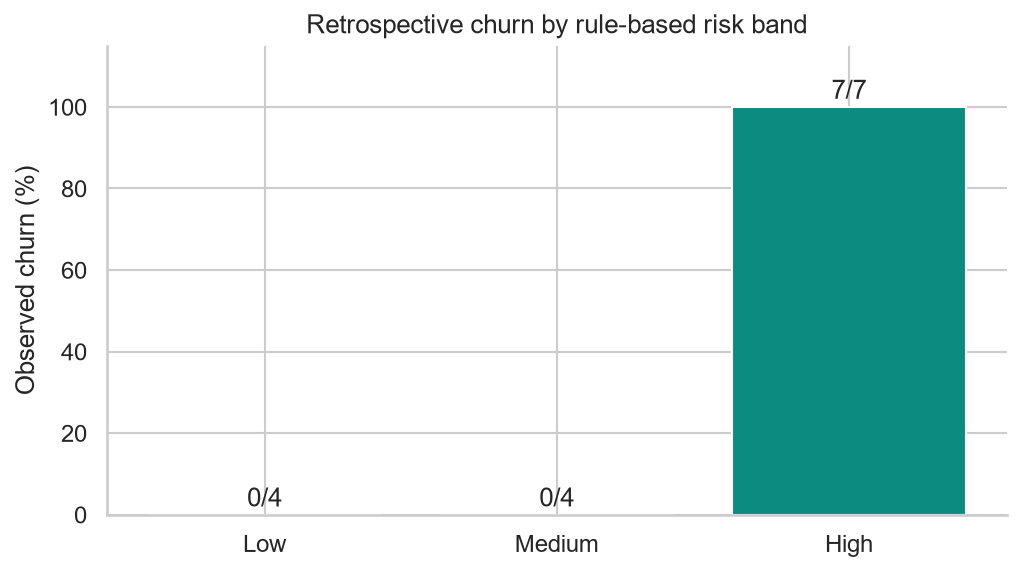

,RiskBand,LabeledCustomers,ChurnedCustomers,ObservedChurnPct,SmallSample
0,High,7,7,100.0,False
1,Low,4,0,0.0,True
2,Medium,4,0,0.0,True


Churned,0,1
ContractType,,
Month-to-Month,0,7
One Year,4,0
Two Year,4,0


In [12]:
chart('risk_band_churn')
display(summarize(df,'RiskBand')[['RiskBand','LabeledCustomers','ChurnedCustomers','ObservedChurnPct','SmallSample']])
display(pd.crosstab(df.ContractType,df.Churned))

Interpretation: High has 7/7 churned; Medium 0/4; Low 0/4. High separates observed outcomes, while Low versus Medium does not. These 0%/100% rates are unstable descriptions of a teaching sample. Support and churn share an unverifiable timeline, and no causal interpretation is justified.

## 15. Customer priority analysis
Rank retained accounts separately from already-churned records. Charge sums include historical monthly amounts unless explicitly restricted. They are neither expected loss nor verified current recurring revenue.

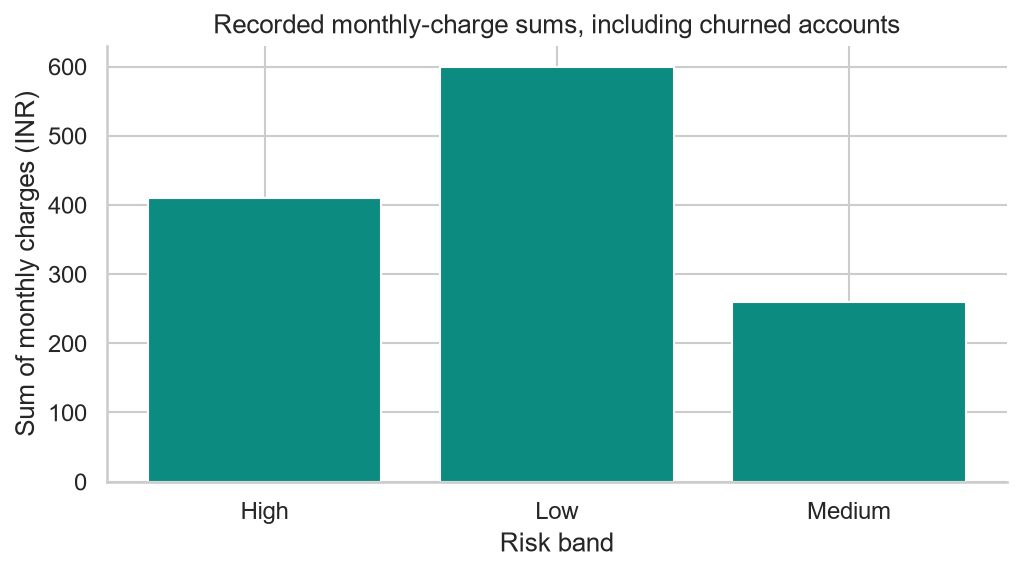

,AnalysisID,PrimarySegment,RiskScore,RiskBand,MonthlyCharges
1,SYN-e5a10dfc6978,Annual commitment,40,Medium,79.99
8,SYN-be498ae37c70,Annual commitment,40,Medium,79.99
5,SYN-c03569c30554,Annual commitment,30,Medium,49.99
12,SYN-50dcab10b966,Annual commitment,30,Medium,49.99
3,SYN-f946d1c542f0,Two-year commitment,20,Low,149.99
7,SYN-ea83f48d2086,Two-year commitment,20,Low,149.99
10,SYN-d6e71793dd14,Two-year commitment,20,Low,149.99
14,SYN-4b02dcb0c31c,Two-year commitment,20,Low,149.99


Retained High accounts: 0
Recorded charge sum, all accounts (INR): 1269.85
Recorded High-band charge sum (INR): 409.93
Recorded retained-account charges (INR): 859.92


In [13]:
chart('charge_exposure')
retained = df.loc[df.Churned.eq(0)].sort_values(['RiskScore','MonthlyCharges'],ascending=False)
display(retained[['AnalysisID','PrimarySegment','RiskScore','RiskBand','MonthlyCharges']])
print('Retained High accounts:', len(retained.loc[retained.RiskBand.eq('High')]))
print('Recorded charge sum, all accounts (INR):', round(df.MonthlyCharges.sum(),2))
print('Recorded High-band charge sum (INR):', round(df.loc[df.RiskBand.eq('High'),'MonthlyCharges'].sum(),2))
print('Recorded retained-account charges (INR):', round(retained.MonthlyCharges.sum(),2))

Interpretation: INR 409.93 belongs to already-churned High-band accounts, so none is a current high-priority retention candidate. The eight retained accounts have INR 859.92 in recorded monthly charges. The sample cannot estimate recoverable revenue or treatment ROI.

## 16. Recommended retention interventions
Investigate onboarding and support themes for the six first-year flexible records; review the singleton case qualitatively. Collect renewal dates before any one-year renewal pilot. Maintain service and feedback for two-year accounts. Do not penalize payment methods without failed-payment evidence. The [recommendation memo](../reports/Customer_Retention_Recommendation_Memo.md) contains the full action matrix, target audiences, KPIs and experiment plan. On a larger dated active cohort, preregister rules and compare randomized assistance against usual service over 90 days, including margin, complaints and opt-out guardrails.

## 17. Limitations and risks
Synthetic n=15, mildly imbalanced 7/8 labels, tiny subgroups, complete contract/label confounding, correlated indicators, unknown snapshot times and outcome horizon. No usage, satisfaction, payment failures, contact permissions, margin or intervention outcomes. No probability calibration or external validation. Account fields may be post-outcome snapshots; temporal verification is mandatory before prospective use. Source rights are distinct from the original code license. Do not substitute real customer data into the public report.

## 18. Conclusion
This project supplies reproducible cohorts, point-level explanations and a testable operational hypothesis. Observed High-band separation adds no established predictive value beyond contract. Start with service investigation and a controlled prospective pilot, keeping already-churned customers out of a retention queue.

In [14]:
for file in ['customer_segments.csv','customer_risk_scores.csv','segment_summary.csv','data_dictionary.csv','scoring_specification.csv']:
    assert (ROOT/'outputs'/file).is_file()
exported=pd.read_csv(ROOT/'outputs/customer_segments.csv')
assert len(exported)==len(df) and exported.AnalysisID.is_unique
assert exported.RiskScore.tolist()==df.RiskScore.tolist()
print(f'Export checks passed for {len(exported)} customers. Required artifacts are present.')

Export checks passed for 15 customers. Required artifacts are present.
